# CitizenSense — NLP-Based Public Feedback Classification and Insight System

AIRI Team PITB — AI Internship Task 4

This notebook walks through the full pipeline: dataset generation, preprocessing, baseline model training & evaluation, the Hugging Face sentiment component, keyword extraction / summarization, and error analysis.

> Learning prototype. Dataset is synthetic (template-generated), not real citizen complaint data.

In [1]:
import os, sys, json
import pandas as pd

PROJECT_ROOT = os.path.abspath('..')
sys.path.insert(0, os.path.join(PROJECT_ROOT, 'app'))
pd.set_option('display.max_colwidth', 120)

## 1. Dataset

Generated by `data/generate_dataset.py` from hand-written templates across 8 categories, including a small Roman Urdu slice and a deliberately label-ambiguous slice (same vague wording mapped to a random plausible category) to produce realistic classification difficulty.

In [2]:
raw_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'data', 'raw', 'citizen_feedback_raw.csv'))
print('Total raw samples:', len(raw_df))
raw_df.head(10)

Total raw samples: 739


,text,category,sentiment,priority,language
0,"near the park ka park ab bohat acha maintain hota hai, shukriya",General,Positive,Low,roman_ur
1,The hospital staff near the old town was unhelpful and the waiting time was too long.,Health,Negative,High,en
2,What is the scheduled water supply timing for near the park?,Water Supply,Neutral,Medium,en
3,Trash is piling up near model town and attracting stray animals and insects.,Sanitation,Negative,High,en
4,When will the road repair work in the village be completed?,Roads / Infrastructure,Neutral,Medium,en
5,The free medical camp organized in our street was really beneficial for residents.,Health,Positive,Low,en
6,Asking if a vaccination camp is planned for the main road soon.,Health,Neutral,Medium,en
7,Frequent power outages in sector G-9 are damaging our appliances since last month.,Electricity,Negative,Urgent,en
8,There is a problem in our street that needs attention.,Electricity,Negative,Medium,en
9,The situation in phase 2 has not improved despite complaints.,Education,Negative,Medium,en


In [3]:
print('Category distribution:')
print(raw_df['category'].value_counts())
print('\nSentiment distribution:')
print(raw_df['sentiment'].value_counts())
print('\nPriority distribution:')
print(raw_df['priority'].value_counts())
print('\nLanguage distribution:')
print(raw_df['language'].value_counts())

Category distribution:
category
Roads / Infrastructure    128
Electricity                99
Water Supply               98
Health                     97
Sanitation                 86
General                    84
Traffic                    75
Education                  72
Name: count, dtype: int64

Sentiment distribution:
sentiment
Negative    492
Neutral     129
Positive    118
Name: count, dtype: int64

Priority distribution:
priority
High      256
Medium    243
Low       186
Urgent     54
Name: count, dtype: int64

Language distribution:
language
en          696
roman_ur     43
Name: count, dtype: int64


## 2. Preprocessing

`data/preprocess.py` cleans text (lowercasing, URL/phone removal, punctuation handling, whitespace normalization), removes duplicates, tokenizes, encodes labels, and performs a stratified 70/15/15 train/val/test split. See README.md Section 3 for the full rationale table of which steps were applied and why.

In [4]:
train_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'data', 'processed', 'train.csv'))
val_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'data', 'processed', 'val.csv'))
test_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'data', 'processed', 'test.csv'))
print(f'Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}')
train_df[['text', 'clean_text', 'category', 'sentiment', 'priority']].head(8)

Train: 517  Val: 111  Test: 111


,text,clean_text,category,sentiment,priority
0,The new street lights installed in the industrial zone work really well.,the new street lights installed in the industrial zone work really well.,Electricity,Positive,Low
1,There is severe traffic congestion on our neighborhood every morning for a week.,there is severe traffic congestion on our neighborhood every morning for a week.,Traffic,Negative,High
2,There is a huge pothole on phase 2 that is causing accidents since morning.,there is a huge pothole on phase 2 that is causing accidents since morning.,Roads / Infrastructure,Negative,High
3,No electricity in the industrial zone since morning.,no electricity in the industrial zone since morning.,Electricity,Negative,Medium
4,Please resolve the issue in the colony as soon as possible.,please resolve the issue in the colony as soon as possible.,General,Negative,Medium
5,The water supply line near sector F-11 is leaking badly and wasting a lot of water.,the water supply line near sector f 11 is leaking badly and wasting a lot of water.,Water Supply,Negative,High
6,No doctor was available at the health center in block C for months.,no doctor was available at the health center in block c for months.,Health,Negative,High
7,There are not enough textbooks available for students in block C.,there are not enough textbooks available for students in block c.,Education,Negative,Medium


## 3. Baseline model: TF-IDF + Logistic Regression

Trained by `train_model.py` (run from the project root: `python train_model.py`). Results below are loaded from the saved evaluation outputs.

In [5]:
with open(os.path.join(PROJECT_ROOT, 'outputs', 'metrics_summary.json')) as f:
    metrics = json.load(f)
metrics

{'val_accuracy': 0.9459459459459459,
 'test_accuracy': 0.9279279279279279,
 'test_precision_weighted': 0.9333762333762333,
 'test_recall_weighted': 0.9279279279279279,
 'test_f1_weighted': 0.9286925015412123,
 'n_train': 517,
 'n_val': 111,
 'n_test': 111,
 'classes': ['Education',
  'Electricity',
  'General',
  'Health',
  'Roads / Infrastructure',
  'Sanitation',
  'Traffic',
  'Water Supply']}

In [6]:
with open(os.path.join(PROJECT_ROOT, 'outputs', 'classification_report.txt')) as f:
    print(f.read())

CitizenSense Baseline Model (TF-IDF + Logistic Regression)
Validation accuracy: 0.9459
Test accuracy: 0.9279
Test weighted precision: 0.9334
Test weighted recall: 0.9279
Test weighted F1-score: 0.9287

Per-class report:
                        precision    recall  f1-score   support

             Education       1.00      0.91      0.95        11
           Electricity       1.00      1.00      1.00        15
               General       0.80      0.92      0.86        13
                Health       0.87      0.93      0.90        14
Roads / Infrastructure       1.00      0.95      0.97        19
            Sanitation       0.93      1.00      0.96        13
               Traffic       1.00      0.83      0.91        12
          Water Supply       0.86      0.86      0.86        14

              accuracy                           0.93       111
             macro avg       0.93      0.92      0.93       111
          weighted avg       0.93      0.93      0.93       111



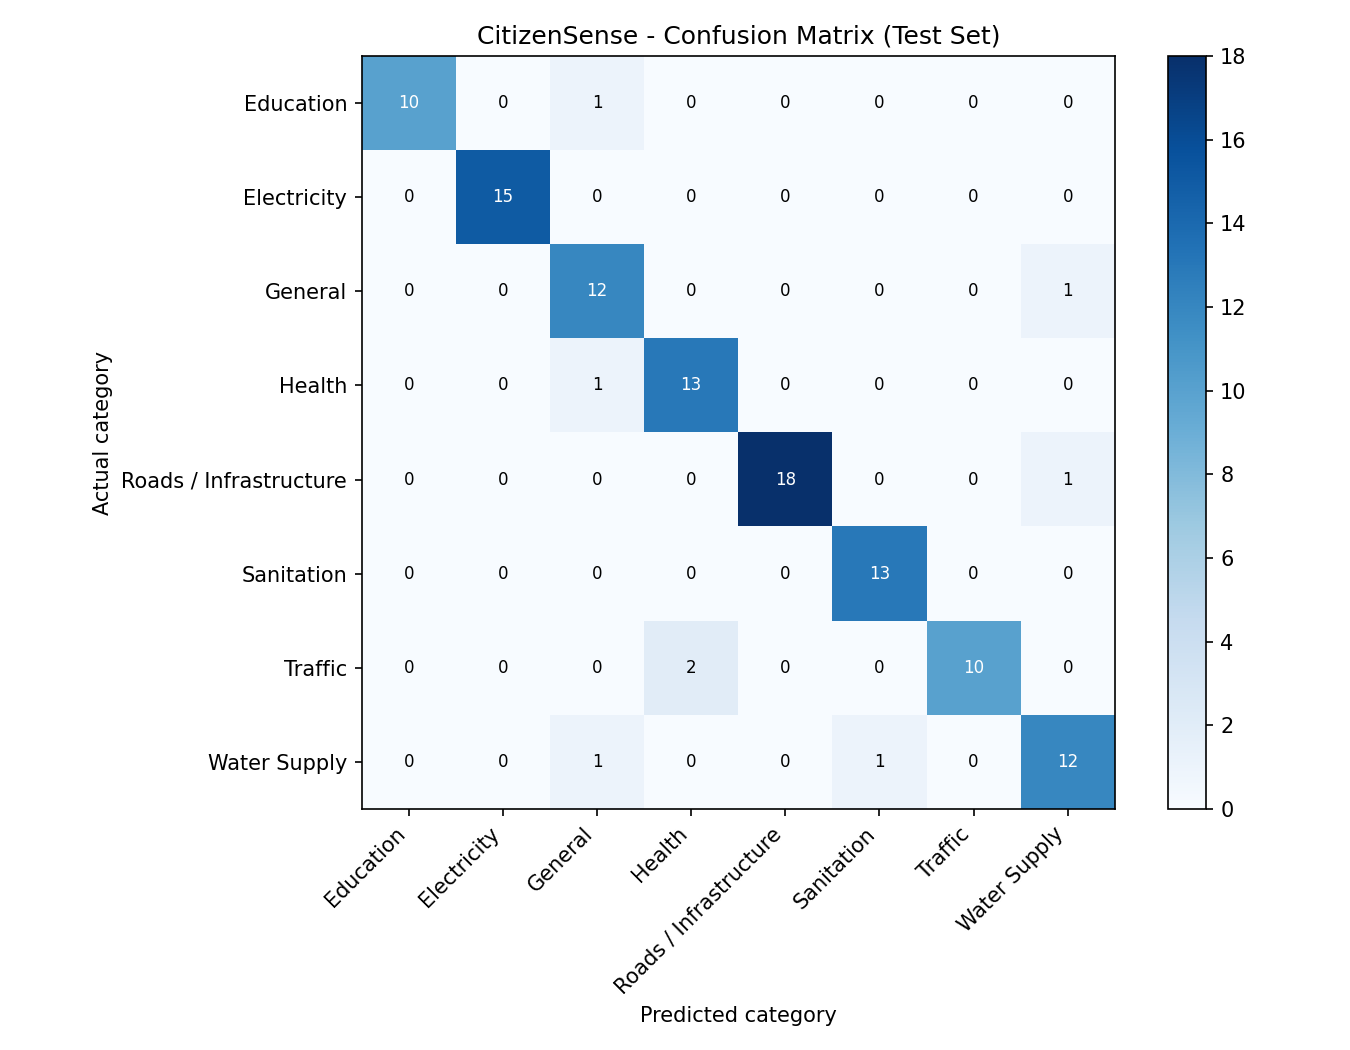

In [7]:
from IPython.display import Image
Image(os.path.join(PROJECT_ROOT, 'outputs', 'confusion_matrix.png'))

In [8]:
sample_preds = pd.read_csv(os.path.join(PROJECT_ROOT, 'outputs', 'sample_predictions.csv'))
sample_preds.head(20)

,text,category,predicted_category,correct,sentiment,priority,language
0,"sector G-9 mein traffic signal kaam nahi kar raha, roz jam lagta hai",Traffic,Traffic,True,Negative,Medium,roman_ur
1,Traffic police presence near the colony has reduced congestion a lot.,Traffic,Traffic,True,Positive,Low,en
2,The situation in our area has not improved despite complaints.,Health,General,False,Negative,Medium,en
3,The street in our neighborhood is damaged and sewage water is flowing over it.,Roads / Infrastructure,Roads / Infrastructure,True,Negative,High,en
4,The situation in sector F-11 has not improved despite complaints.,Education,General,False,Negative,Medium,en
5,There is severe traffic congestion on sector G-9 every morning since last night.,Traffic,Traffic,True,Negative,High,en
6,The water supply line near our area is leaking badly and wasting a lot of water.,Water Supply,Water Supply,True,Negative,High,en
7,"our street mein since last month se paani nahi aa raha, bohat pareshani ho rahi hai",Water Supply,Water Supply,True,Negative,High,roman_ur
8,The water we receive in sector F-11 is dirty and unsafe to drink.,Water Supply,Water Supply,True,Negative,High,en
9,"Street construction in the village has been abandoned halfway, blocking traffic for three days.",Roads / Infrastructure,Roads / Infrastructure,True,Negative,High,en


## 4. Hugging Face transformer component: sentiment pipeline

`app/sentiment.py` wraps the pretrained `sentiment-analysis` pipeline (DistilBERT fine-tuned on SST-2), adding a confidence threshold to fall back to **Neutral** when the model isn't confident. This satisfies the task's transformer/Hugging Face requirement.

In [9]:
from sentiment import predict_sentiment

examples = [
    'There is no water supply in our area for three days.',
    'The newly repaired road is smooth and well done, thank you.',
    'When will the road repair work be completed?',
]
for ex in examples:
    print(ex, '->', predict_sentiment(ex))

C:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1953.68it/s]

There is no water supply in our area for three days. -> ('Negative', 0.9980289340019226)
The newly repaired road is smooth and well done, thank you. -> ('Positive', 0.9998606443405151)
When will the road repair work be completed? -> ('Negative', 0.9992384910583496)


In [10]:
with open(os.path.join(PROJECT_ROOT, 'outputs', 'sentiment_evaluation.txt')) as f:
    print(f.read())

CitizenSense - Hugging Face sentiment pipeline evaluation (zero-shot)
Model: distilbert-base-uncased-finetuned-sst-2-english (+ neutral threshold 0.70)
Test accuracy: 0.7477

              precision    recall  f1-score   support

    Negative       0.79      0.91      0.85        78
     Neutral       0.33      0.05      0.08        21
    Positive       0.61      0.92      0.73        12

    accuracy                           0.75       111
   macro avg       0.58      0.62      0.55       111
weighted avg       0.68      0.75      0.69       111



## 5. Keyword extraction & summarization

In [11]:
from utils import extract_keywords, generate_summary, suggested_department

sample_text = 'The hospital staff was helpful but the waiting time was too long and medicines were out of stock.'
category_guess = 'Health'
print('Keywords:', extract_keywords(sample_text))
print('Summary :', generate_summary(sample_text, category_guess))
print('Department:', suggested_department(category_guess))

Keywords: ['helpful', 'medicines', 'time long', 'waiting', 'waiting time']
Summary : Citizen reports a health issue: the hospital staff was helpful but the waiting time was too long and medicines were out of stock.
Department: Health Department


## 6. Full CitizenSense insight card (category + sentiment + priority + keywords + summary + department)

In [12]:
from inference import CitizenSenseAnalyzer
analyzer = CitizenSenseAnalyzer()
result = analyzer.analyze(
    'The road in our area has been broken for months and rainwater collects every day. Please fix it urgently.'
)
result

{'category': np.str_('Roads / Infrastructure'),
 'category_confidence': 0.599,
 'sentiment': 'Negative',
 'sentiment_confidence': 0.883,
 'priority': 'High',
 'keywords': ['road area',
  'collects',
  'collects day',
  'day fix',
  'fix urgently'],
 'summary': 'Citizen reports a roads / infrastructure issue: the road in our area has been broken for months and rainwater collects every day. please fix it urgently.',
 'suggested_department': 'Municipal / Infrastructure Department'}

## 7. Error analysis

At least 15 incorrect or low-confidence predictions, manually reviewed with an inferred error type and possible reason. See `error_analysis.py` and README.md Section 7 for the full discussion and suggested improvements.

In [13]:
error_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'outputs', 'error_analysis.csv'))
error_df

,Text Sample,Actual Label,Predicted Label,Confidence,Error Type,Possible Reason
0,Please resolve the issue in our area as soon as possible.,Health,Health,0.182,Low-confidence (weak) prediction,Model was not confident even though the prediction was correct; text lacks a strong category-specific keyword.
1,Please resolve the issue in sector G-9 as soon as possible.,Traffic,Health,0.183,Wrong category,Ambiguous/generic wording without a strong category-specific keyword
2,We have been facing this problem in the housing scheme since last month.,Water Supply,Electricity,0.213,Wrong category,Ambiguous/generic wording without a strong category-specific keyword
3,Please resolve the issue in the main market as soon as possible.,Traffic,Health,0.218,Wrong category,Ambiguous/generic wording without a strong category-specific keyword
4,We have been facing this problem in sector F-11 for three days.,Water Supply,Sanitation,0.226,Wrong category,Ambiguous/generic wording without a strong category-specific keyword
5,We have been facing this problem in our street for three days.,Electricity,Water Supply,0.231,Wrong category,Ambiguous/generic wording without a strong category-specific keyword
6,The situation in sector F-11 has not improved despite complaints.,Education,General,0.264,Wrong category,Ambiguous/generic wording without a strong category-specific keyword
7,No action has been taken in the colony for a long time.,Roads / Infrastructure,Water Supply,0.272,Wrong category,Contains both road and water issue
8,The situation in our area has not improved despite complaints.,Health,General,0.291,Wrong category,Vague wording also plausible as a general complaint
9,"This is a serious issue in near the park, please look into it urgently.",General,Health,0.292,Wrong category,Vague wording also plausible as a general complaint


## 8. Conclusion

CitizenSense demonstrates a complete NLP lifecycle for public feedback analysis: synthetic data generation and labeling, preprocessing, a TF-IDF + Logistic Regression baseline (92.8% test accuracy), a Hugging Face pretrained sentiment pipeline, keyword extraction, templated summarization, confusion-matrix/F1 evaluation, manual error analysis with concrete improvement suggestions, and three interchangeable demo interfaces (CLI, Streamlit, FastAPI). See `README.md` for the full write-up and `report/final_report.md` / `report/linkedin_portfolio_report.md` for the portfolio-ready summary.